In [14]:
import networkx as nx

In [15]:
import matplotlib.pyplot as plt

# Manual de uso para Networkx

## Procedimental y comandos necesarios para realizar los diferentes tipos de problemas

### 1) del árbol de expansión mínima.
### 2) de la ruta más corta.
### 3) del flujo máximo.

### Para 1) y 2) use como ejemplo la red de la imagen anexa "actividad_1_a,png";  para 1) considere la versión no dirigida de la red.
### Para 3) use como ejemplo la red de la imagen anexa "actividad_1_b.png".

### Imagen Referencia actividad 1 
![actividad_1_a](actividad_1_a.png)

# 1.- Introducción
Una red consiste en una serie de nodos enlazados con arcos (o ramas). La notación para describir una red es (N, A), donde N es el conjunto de nodos y A es el conjunto de arcos.

Aqui se estudian los diferentes problemas de redes mediante el lenguaje de programacion python ocupando las herramientas que nos ayuda a manejar de una manera más optima es, en su parte la seccion anaconda, en conjunto con Jupyter para la realizacion de modelos de redes. Con cada red se asocia algún tipo de flujo (por ejemplo, flujo de productos petroleros
en un oleoducto y flujos de tráfico de automóviles en carreteras). 

En general, el flujo en una red está limitado por la capacidad de sus arcos, que pueden ser finitos o infinitos.

Se dice que un arco es dirigido u orientado si permite un flujo positivo en una dirección,
y flujo cero en la dirección opuesta. Una red dirigida tiene todos sus arcos dirigidos.

Por lo tanto se prioriza optimizar el uso de recursos y resolver problemas como:

- Diseño de gasoductos.
- Rutas más cortas entre dos ciudades.
- Flujo de costos minimo de campos petroleros hasta refinerias.
- Determinacioón del cronograma de un proyecto o actividad.

### 1.1 Conceptos fundamentales

Un grafo o red es una estructura matemática que permite representar
relaciones o conexiones entre diferentes elementos.

Un grafo está compuesto principalmente por dos elementos:

- *Vértices o nodos:* representan los elementos de la red.
- *Arcos o Aristas:* representan las conexiones entre los nodos.

Matemáticamente, un grafo puede representarse como:

$$
G=(V,E)
$$

donde:

- $V$ representa el conjunto de vértices o nodos.
- $E$ representa el conjunto de aristas o conexiones (tambien delimitado como arcos).

Esto se traduce literalmente en el lenguaje de programacion como: 

$$G=nx.Graph()$$

Donde $G$ es nuestro Grafo
si lo queremos visualizar seria de la siguiente manera:

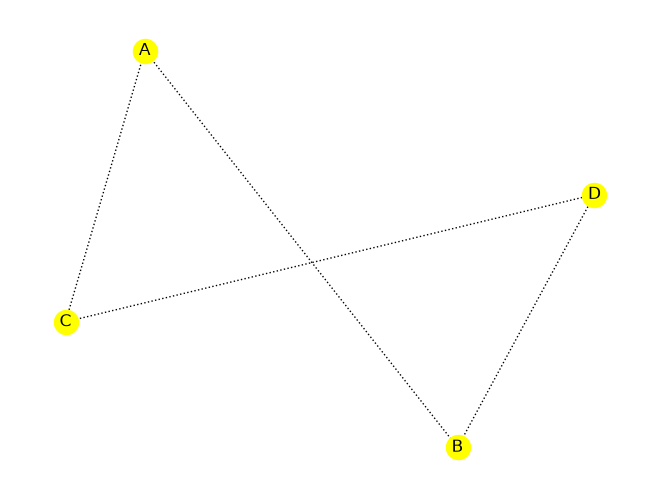

In [36]:
G = nx.Graph()
G.add_edges_from([
("A","B"),
    ("A","C"),
    ("B","D"),
    ("D","C"),
])
nx.draw(G,with_labels =True, style="dotted",node_color='yellow')

Para ello tenemos el siguiente ejemplo:

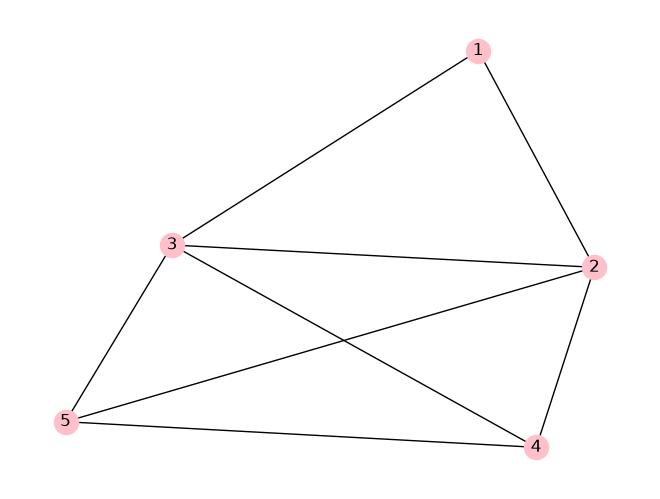

In [43]:
Ejemplo_2 =[
    ("1","2"),
    ("1","3"),
    ("2","3"),
    ("2","5"),
    ("3","4"),
    ("3","5"),
    ("4","2"),
    ("4","5")
    ]
# Creamos el grafo
G = nx.Graph()
G.add_edges_from(Ejemplo_2)
nx.draw(G,with_labels = True, node_color = 'pink')

Una ruta es una sucesión de arcos distintos que unen dos nodos pasando por otros nodos,
independientemente de la dirección de flujo en cada arco. Una ruta forma un ciclo si conecta un
nodo consigo mismo, pasando por otros nodos. Por ejemplo, en la Anterior, los arcos $(2,3)$ ,$(3,5)$ y $(5,2)$ forman un bucle o circuito cerrado. Un ciclo es dirigido si consiste en una ruta dirigida, por ejemplo $(2,3)$, $(3,4)$ y $(4,2)$ .

## Partes de una red

Las partes fundamentales de una red son:

- Una ruta: Sucesion de arcos distintos que une dos nodos, pasando por otros, sin importar la direccion del flujo.
- Un cliclo: Ruta que conecta un nodo consigo mismom pasando por otros nodos.
- Un Ciclo dirigido: Es un cliclo que tambien se cosidera una ruta dirigida ( con direccion, asimismo tambien hay no dirigida o en este caso en particular ciclo no dirigido.
- Un árbol: Red conectada que puede usar un subconjunto de nodos (no permite ciclos).
- Un arbol de expansión: Es el que incluye todos los nodos de la red.

# Algoritmo del Árbol de Expansión Minima

## Objetivo:
Conectar todos los nodos de una red no dirigida con el costo / distancia minimo. Solo aplica a redes no dirigidas.

### Definiciones

- $N =(1,2,3,...,n)$: Conjunto de nodos de la red.
- $C_k$ : Conjunto de nodos conectados de forma permanente en la interacción $K$
- $C^*_k$ : Conjunto de nodos que todavia deben conectarse de forma permanente.

### pasos para la realizacion 

- $Paso\: 0$:
  $C_0 = 0\;;\; C^*_o = N$
- $Paso\:1$: comienza con cualquier nodo {$i$} de $C^*_0$; hacer $C_1= ${$i$}$\;;\; C^*_1 =N-${$i$}
- Paso General ($K$):
  - Seleccionar nodo $j^*$ en $C^*_{k-1}$ que produzca el arco más corto hacia un nodo ya conectado en $C_{k-1}$
  - Enlazar $j^*$ de forma permanente:
    $$C_k=C_{k-1} x U(i^*)$$
    $$C^*_k \; = \; C^*_{k-1}-(j^*)$$
  - Si $C^*_k = 0\; → \;\; detenerse$. si no, $K=K+1$ y repetir.

## Ejemplo paso a paso numero 1

Se busca la red de cable más economica que conecte 6 puntos:

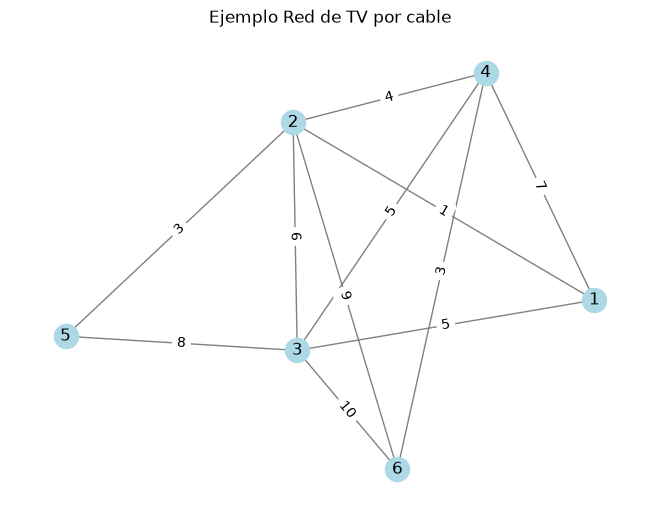

In [54]:
G= nx.Graph()
Ejemplo_Dinamico_1 =[
    ("1","2",1),
    ("1","3",5),
    ("1","4",7),
    ("2","3",6),
    ("2","4",4),
    ("2","5",3),
    ("2","6",9),
    ("3","4",5),
    ("3","5",8),
    ("3","6",10),
    ("4","6",3)
]
G.add_weighted_edges_from(Ejemplo_Dinamico_1)
# Posiciones de los nodos
pos = nx.spring_layout(G, seed=100)

# Dibujar nodos y aristas
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray")

# Mostrar los pesos de cada arista
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

plt.title("Ejemplo Red de TV por cable")
plt.show()

### Definimos la Grafo (red)
$$G = nx.Graph()$$
$$Nombre= [...]$$
$$G.add\;weighted\;edges\;from(Nombre)$$
De esta manera se define la red:
### Posiciones de los nodos
$$pos = nx.spring layout(G, seed=100)$$
### Dibujar nodos y aristas
$$nx.draw(G, pos, with labels=True, node color="lightblue", edge color="gray")$$

### Mostrar los pesos de cada arista
$$nx.draw_networkx_edge_labels(G, pos, edge labels=nx.get edge attributes(G, "weight"))$$

### Agregar titulo a la red de nodos (grafo)
$$plt.title("\;...\;")$$
$$plt.show()$$

## Ejemplo dinamico 2 Red O,A,B,C,D,E,T

Para ejemplificar de una mejor manera empleamos un segundo ejemplo de o hasta T

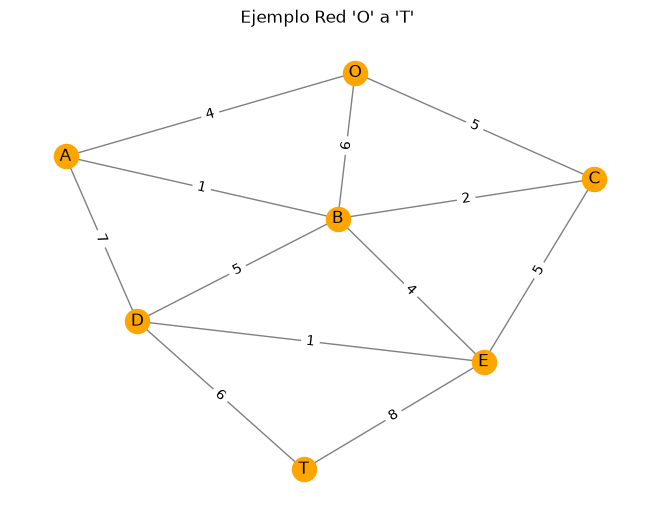

In [57]:
G= nx.Graph()
Ejemplo_Dinamico_2 =[
    ("O","A",4),
    ("O","B",6),
    ("O","C",5),
    ("B","A",1),
    ("A","D",7),
    ("B","C",2),
    ("B","D",5),
    ("B","E",4),
    ("C","E",5),
    ("D","E",1),
    ("D","T",6),
    ("E","T",8),
]
G.add_weighted_edges_from(Ejemplo_Dinamico_2)
# Posiciones de los nodos
pos = nx.spring_layout(G, seed=100)

# Dibujar nodos y aristas
nx.draw(G, pos, with_labels=True, node_color="orange", edge_color="gray")

# Mostrar los pesos de cada arista
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

plt.title("Ejemplo Red 'O' a 'T' ")
plt.show()

Ruta más corta de 1 a 7: [1, 2, 4, 7]
Costo total: 12


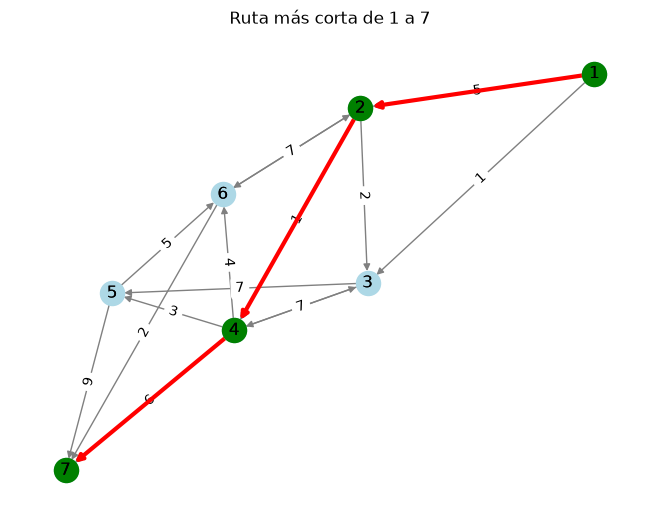

In [62]:
# Definimos el grafo dirigido
G = nx.DiGraph()
G.add_weighted_edges_from([
    (1, 2, 5),
    (1, 3, 1),
    (2, 3, 2),
    (2, 4, 1),
    (2, 6, 6),
    (6, 2, 7),
    (3, 4, 6),
    (3, 5, 7),
    (4, 3, 7),
    (4, 5, 3),
    (4, 6, 4),
    (4, 7, 6),
    (5, 6, 5),
    (5, 7, 9),
    (6, 7, 2)
])

# Calcular la ruta más corta de 1 a 7
ruta = nx.shortest_path(G, source=1, target=7, weight="weight")
costo = nx.shortest_path_length(G, source=1, target=7, weight="weight")
print("Ruta más corta de 1 a 7:", ruta)
print("Costo total:", costo)

# Dibujar el grafo
pos = nx.spring_layout(G, seed=1000)
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

# Resaltar la ruta más corta
ruta_edges = list(zip(ruta, ruta[1:]))
nx.draw_networkx_edges(G, pos, edgelist=ruta_edges, edge_color="red", width=3)
nx.draw_networkx_nodes(G, pos, nodelist=ruta, node_color="green")
nx.draw_networkx_labels(G, pos)

plt.title("Ruta más corta de 1 a 7")
plt.show()

El ejemplo anterior ya incluimos los comandos de ruta más corta o los valores más cortos a una ruta especifica del 1 al 7, lo cual es lo más adecuado, sin en bargo tambien abarcamos el comando de distancia más corta que abarcaremos en el siguiente tema, por lo que es necesario tener un listado de los comandos en conjunto con su funcionalidad basica.

# Comandos básicos para MST
## Comandos basicos y definiciones 

Por si no queda al 100% abarcado los comandos requeridos mostraremos el listado de comandos.

- Crear un grafo no dirigido
  
  G = nx.Graph()
  Inicializa un grafo donde las aristas no tienen dirección.

- Agregar aristas con pesos
  
  G.add_weighted_edges_from([("1","2",1), ("1","3",5), ("2","4",4)])
  Cada tupla (u, v, w) representa una conexión entre nodos u y v con peso w.
  
- Calcular el Árbol de Expansión Mínima
  
  mst = nx.minimum_spanning_tree(G)
  Aplica automáticamente algoritmos como Kruskal o Prim para obtener el MST.
  
- Dibujar el grafo
  
  pos = nx.spring_layout(G, seed=42)

  nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray")

  Genera la visualización del grafo con nodos y aristas.

- Mostrar los pesos de las aristas

  nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

  Coloca los valores de cada arista sobre las líneas del grafo.

- Dibujar el MST resaltado

  nx.draw(mst, pos, with_labels=True, node_color="lightgreen", edge_color="black")

  Dibuja solo las aristas seleccionadas en el MST.

- Listar las aristas del MST

  print(mst.edges(data=True))

  Muestra las aristas que forman el árbol mínimo junto con sus pesos.

- Calcular el costo total del MST

  costo_total = sum(data["weight"] for u, v, data in mst.edges(data=True))
print("Costo total:", costo_total)


# Problema de la ruta más corta

## Dediniciones:
Red convexa no dirigida con dos nodos especiales, origen y destino; cada arco tiene una distancia no negativa.
## Objetivo:
Hallar la trayectoria de distancia total mínima del origen al destino.
## Algoritmo:
- Objetivo de la interación $n$: Encontrar el n-esimo nodo más cercano al origen. Repartir hasta que ese nodo sea el destino.
- Nodos resueltos: los $n-1$ nodos ya identificados (con su ruta más corta y distancia desde el origen). Los demás son no resueltos.
- Candidato al n-ésimo nodo más cercano: Cualquier nodo no resuelto conectado directamente a uno o más nodos resueltos; se toma el que tema la ligadura más corta ( los empates dan candidatos adicionales).
- Cálculo: Para cada nodo resuelto y sus candidatos, su suma la distancia del arco + la distancia minima ya conocida del nodo resuelto. El Candidato con la distancia total más pequeña es el n-ésimo nodo resuelto ( empates → nodos resueltos adicionales).

Por lo que lo podemos visualizar con el siguiente ejemplo:

In [63]:
# Grafo dirigido con pesos
G = nx.DiGraph()
G.add_weighted_edges_from([
    (1, 2, 5),
    (1, 3, 1),
    (2, 3, 2),
    (2, 4, 1),
    (3, 4, 6),
    (4, 5, 3),
    (5, 6, 5),
    (6, 7, 2)
])

# Ruta más corta de 1 a 7
ruta = nx.shortest_path(G, source=1, target=7, weight="weight")
costo = nx.shortest_path_length(G, source=1, target=7, weight="weight")

print("Ruta más corta:", ruta)
print("Costo total:", costo)

Ruta más corta: [1, 2, 4, 5, 6, 7]
Costo total: 16


Este comando abarca solo la ruta más corta establecida de forma corta y su costo total ya que tienen cada arista un peso, distancia, tamaño, etc.
En el problema de la ruta más corta se determina ésta, entre una fuente y un destino, en una red de transporte. Hay otras soluciones que se pueden representar con el mismo modelo, como se ve en los ejemplos siguientes.

### Aplicaciones reales

- GPS y navegación: encontrar trayectos más rápidos.

- Redes de internet: decidir por qué camino enviar paquetes.

- Logística: optimizar rutas de entrega.

- Videojuegos: IA que calcula movimientos óptimos en mapas.

- Emergencias: ambulancias y bomberos que buscan la ruta más rápida.

Tenemos un ejemplo visualizado tomando de referencia la siguiente imagen:

### Imagen Referencia actividad 1 
![actividad_1_a](actividad_1_a.png)

Ruta más corta de Imagen: [1, 2, 4, 7]
Costo total: 12


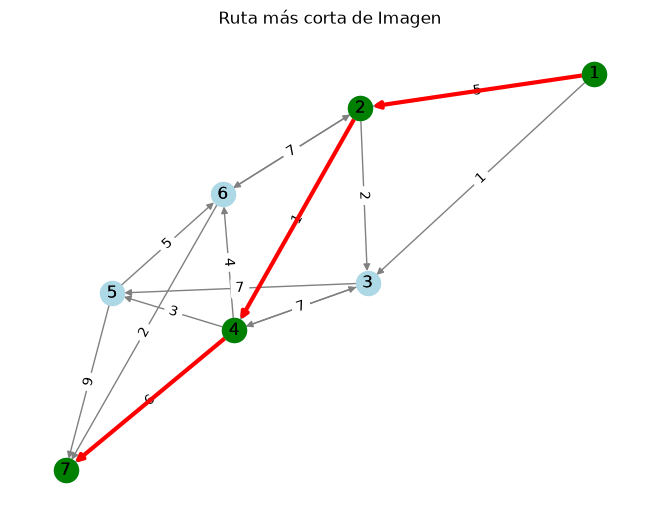

In [71]:
# Definimos el grafo dirigido
G = nx.DiGraph()
G.add_weighted_edges_from([
    (1, 2, 5),
    (1, 3, 1),
    (2, 3, 2),
    (2, 4, 1),
    (2, 6, 6),
    (6, 2, 7),
    (3, 4, 6),
    (3, 5, 7),
    (4, 3, 7),
    (4, 5, 3),
    (4, 6, 4),
    (4, 7, 6),
    (5, 6, 5),
    (5, 7, 9),
    (6, 7, 2)
])

# Calcular la ruta más corta de 1 a 7
ruta = nx.shortest_path(G, source=1, target=7, weight="weight")
costo = nx.shortest_path_length(G, source=1, target=7, weight="weight")
print("Ruta más corta de Imagen:", ruta)
print("Costo total:", costo)

# Dibujar el grafo
pos = nx.spring_layout(G, seed=1000)
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

# Resaltar la ruta más corta
ruta_edges = list(zip(ruta, ruta[1:]))
nx.draw_networkx_edges(G, pos, edgelist=ruta_edges, edge_color="red", width=3)
nx.draw_networkx_nodes(G, pos, nodelist=ruta, node_color="green")
nx.draw_networkx_labels(G, pos)

plt.title("Ruta más corta de Imagen")
plt.show()

Ruta más corta de 1 a 7: [1, 3, 5]
Costo total: 80


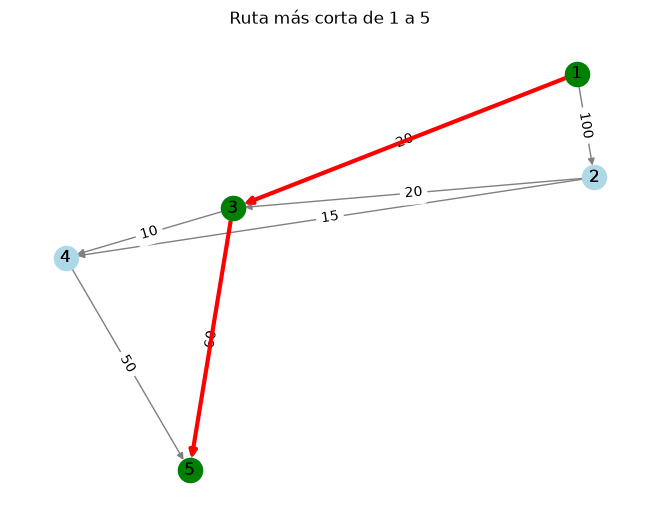

In [72]:
# Definimos el grafo dirigido
G = nx.DiGraph()
G.add_weighted_edges_from([
    (1, 2, 100),
    (1, 3, 20),
    (2, 3, 20),
    (2, 4, 15),
    (3, 4, 10),
    (3, 5, 60),
    (4, 5, 50)
])

# Calcular la ruta más corta de 1 a 5
ruta = nx.shortest_path(G, source=1, target=5, weight="weight")
costo = nx.shortest_path_length(G, source=1, target=5, weight="weight")
print("Ruta más corta de 1 a 7:", ruta)
print("Costo total:", costo)

# Dibujar el grafo
pos = nx.spring_layout(G, seed=36)
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

# Resaltar la ruta más corta
ruta_edges = list(zip(ruta, ruta[1:]))
nx.draw_networkx_edges(G, pos, edgelist=ruta_edges, edge_color="red", width=3)
nx.draw_networkx_nodes(G, pos, nodelist=ruta, node_color="green")
nx.draw_networkx_labels(G, pos)

plt.title("Ruta más corta de 1 a 5")
plt.show()

Ruta más corta de 1 a 7: [1, 3, 6, 8]
Costo total: 29


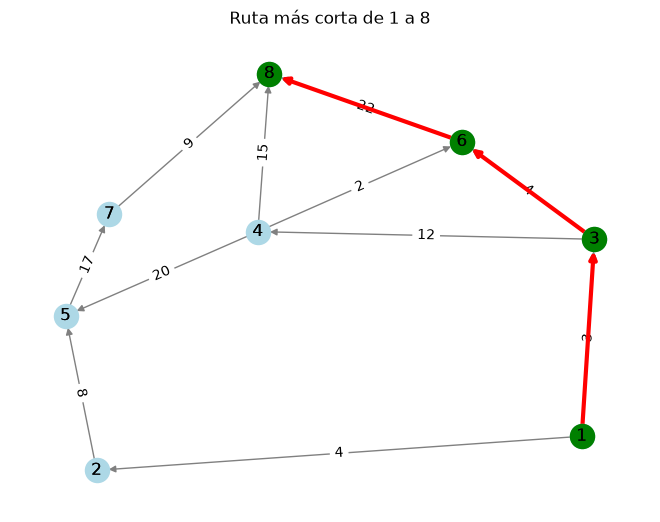

In [70]:
# Definimos el grafo dirigido
G = nx.DiGraph()
G.add_weighted_edges_from([
    (1, 2, 4),
    (1, 3, 3),
    (2, 5, 8),
    (3, 4, 12),
    (3, 6, 4),
    (4, 5, 20),
    (4, 6, 2),
    (4, 8, 15),
    (5, 7, 17),
    (6, 8, 22),
    (7, 8, 9),
])

# Calcular la ruta más corta de 1 a 8
ruta = nx.shortest_path(G, source=1, target=8, weight="weight")
costo = nx.shortest_path_length(G, source=1, target=8, weight="weight")
print("Ruta más corta de 1 a 7:", ruta)
print("Costo total:", costo)

# Dibujar el grafo
pos = nx.spring_layout(G, seed=36)
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

# Resaltar la ruta más corta
ruta_edges = list(zip(ruta, ruta[1:]))
nx.draw_networkx_edges(G, pos, edgelist=ruta_edges, edge_color="red", width=3)
nx.draw_networkx_nodes(G, pos, nodelist=ruta, node_color="green")
nx.draw_networkx_labels(G, pos)

plt.title("Ruta más corta de 1 a 8")
plt.show()

# Problema de Flujo Máximo

## Contexto:
Red dirigida donde cada arco tiene un flujo asociado (capacidad).
## Precisiones:
- Todo flujo se origina en un nodo ( $Origen$ ) y termina en otro ( $destino$ )
- Los demás nodos son nodos de $trastorno$.
- El flujo por un arco solo va en la direccion de la flecha: su cantidad máxima es la $capacidad\;\;del\;\;arco$.
- $Objetivo:$ Maximizar el flujo total del origen al destino.

Imagine una red de oleoductos que transportan crudo desde los pozos hasta las refinerías. En las distancias intermedias adecuadas están instaladas estaciones de bombeo, para mover el crudo por la red. Cada segmento de tubo tiene un flujo (o capacidad) máximo de crudo. Un segmento de tubo puede ser uni o bidireccional, dependiendo de su diseño.

Un segmento unidireccional tiene una capacidad finita en una dirección, y capacidad cero en la dirección opuesta. La siguiente imagen muestra una red de oleoductos. ¿Cómo se puede determinar la capacidad máxima de la red entre los pozos y las refinerías? La solución del problema propuesto requiere convertir la red en una que tenga una sola fuente y un solo “sumidero” o destino. Este requerimiento se llena usando arcos unidireccio-
nales de capacidad infinita, como indican los arcos de línea interrumpida en la figura a continuacion.

### Imagen Referencia actividad 1B
![actividad_1_b](actividad_1_b.png)

Flujo máximo de la red: 25
Distribución de flujo por aristas:
1 → 2: 8
1 → 3: 13
1 → 5: 4
2 → 3: 2
2 → 5: 6
3 → 4: 5
3 → 5: 10
4 → 5: 5


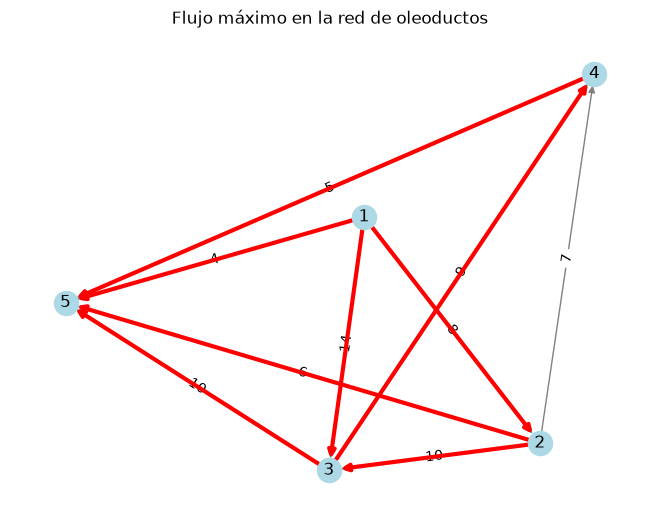

In [74]:


# Creamos el grafo dirigido
G = nx.DiGraph()

# Agregamos las aristas con sus capacidades
G.add_edge(1, 2, capacity=8)
G.add_edge(1, 3, capacity=14)
G.add_edge(1, 5, capacity=4)

G.add_edge(2, 3, capacity=10)
G.add_edge(2, 4, capacity=7)
G.add_edge(2, 5, capacity=6)

G.add_edge(3, 4, capacity=9)
G.add_edge(3, 5, capacity=10)

G.add_edge(4, 5, capacity=5)

# Definimos fuente y sumidero
source, sink = 1, 5

# Calculamos el flujo máximo
flow_value, flow_dict = nx.maximum_flow(G, source, sink)

print("Flujo máximo de la red:", flow_value)
print("Distribución de flujo por aristas:")
for u in flow_dict:
    for v in flow_dict[u]:
        if flow_dict[u][v] > 0:
            print(f"{u} → {v}: {flow_dict[u][v]}")

# Dibujar el grafo con capacidades
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", arrows=True)

# Mostrar capacidades en las aristas
edge_labels = nx.get_edge_attributes(G, "capacity")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

# Resaltar las aristas que llevan flujo
flujo_edges = [(u, v) for u in flow_dict for v in flow_dict[u] if flow_dict[u][v] > 0]
nx.draw_networkx_edges(G, pos, edgelist=flujo_edges, edge_color="red", width=3)

plt.title("Flujo máximo en la red de oleoductos")
plt.show()


En este problema tenemos una red de tuberías que conecta pozos ( $fuente$ ) con refinerías ( $sumidero$ ).
Cada tubería tiene una capacidad máxima de flujo ( cuánto crudo puede transportar ). Algunas conexiones son unidireccionales, lo que significa que el flujo solo puede ir en una dirección.

El objetivo es calcular cuánto crudo como máximo puede llegar desde el pozo hasta la refinería, considerando todas las rutas posibles y las limitaciones de capacidad.

Antes de avanzar con el tema agregaremos un listado de comandos más especializados en el tema de trayectorias aumentadas o flujo maximo.

# Comandos Trayectorias aumentada

## Complementacion de comandos basicos 

### Crear grafo dirigido (para flujos)
G = nx.DiGraph()
Se usa porque los tubos/oleoductos pueden ser unidireccionales.

### Agregar aristas con capacidad
G.add_edge(1, 2, capacity=8)
Cada arista tiene un atributo capacity que indica el máximo flujo permitido.

### Calcular flujo máximo
flow_value, flow_dict = nx.maximum_flow(G, source, sink)
Devuelve el valor total del flujo máximo (flow_value) y cómo se reparte por cada arista (flow_dict).

### Listar distribución del flujo
for u in flow_dict:
    for v in flow_dict[u]:
        if flow_dict[u][v] > 0:
            print(f"{u} → {v}: {flow_dict[u][v]}")
Muestra qué aristas realmente transportan flujo y cuánto.

### Dibujar grafo con capacidades
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "capacity"))
Visualiza el grafo y coloca las capacidades sobre las aristas.

### Resaltar aristas con flujo
flujo_edges = [(u, v) for u in flow_dict for v in flow_dict[u] if flow_dict[u][v] > 0]
nx.draw_networkx_edges(G, pos, edgelist=flujo_edges, edge_color="red", width=3)
Pinta en rojo las aristas que efectivamente llevan flujo en la solución óptima.

## Algoritomo de trayectorias aumentadas

### Red residual:
Red que muestra las capacidades restantes ( Capacidades residuales ) en cada arco, tras asignar un flujo.

 - Se convierte cada arco dirigido en no dirigido ( para "$devolver$" flujo)
 - Ejemplo: Arco "O" a "B" con capacidad 7; si se asigna un flujo de 3, queda "O" a "B" con capacidad residual 3 (direccion opuesta).

### Trayectoria de aumento:
Trayectoria dirigida del origen al destino en la red residual, donde todos sus arcos tienen capacidad residual estrictamente positiva. El minimo de esas capacidades = Capacidad residual de la trayectoria.

## Algoritmo de flujo máximo
El algoritmo de flujo máximo se basa en determinar rutas de irrupción que tengan flujo neto positivo entre los nodos fuente y sumidero. Cada ruta comunica parte o todas las capacidades de sus arcos al flujo total en la red.
Considérese el arco $(i, j)$ con capacidades iniciales . A medida que partes de esas capacidades contribuyen al flujo en el arco, se actualizan los residuales (o capacidades remanentes). La red con los residuales actualizados se llama red residual. Se usará la nota-
ción ($c_{ij}\;,\;c_{ji}$) para representar esos residuales.

Para un nodo j que recibe flujo del nodo i, se define una etiqueta [aj,i], donde $a_j$ es el flujo del nodo i al nodo j. Los pasos del algoritmo se resumen como sigue.

- Paso 1. Para todos los arcos (i, j) se iguala la capacidad residual con la capacidad inicial;
esto es, . Sea a1  y se etiqueta el nodo fuente 1 con [q, ].
Se iguala i  1 y se prosigue en el paso 2.
- Paso 2. Determinar Si, el conjunto de nodos j no etiquetados que se pueden alcanzar direc-
tamente desde el nodo i, con arcos con residuales positivos (esto es, cij 0 para to-
da ). Si , ir al paso 3. En caso contrario ir al paso 4.

- Paso 3. Determinar tal que

Igualar ak  cik y etiquetar el nodo k con [ak,i]. Si k  n, el nodo de sumidero se

ha etiquetado, y se ha encontrado una ruta de irrupción; ir al paso 5. En caso con-
trario, igualar i  k y seguir en el paso 2.

- Paso 4. (Retroceso). Si i  1, no hay otras irrupciones posibles; ir al paso 6. En caso contra-
rio, sea r el nodo que se ha etiquetado inmediatamente antes del nodo actual i y qui-
tar i del conjunto de nodos adyacentes a r. Igualar i  r y continuar en el paso 2.

- Paso 5. (Determinación de la red residual). Sea Np  (1, k1, k2, ..., n); se definen los nodos
de la p-ésima ruta de irrupción del nodo fuente 1 al nodo sumidero n. Entonces el
flujo máximo por la ruta se calcula como

$$fp = mín (a_1, a_{k1},a_{k2},...,a_n)$$

La capacidad residual de cada arco a lo largo de la ruta de irrupción se disminuye en $fp$ unidades en la dirección del flujo y se aumenta $fp$ unidades en la dirección contraria; esto es, para los nodos i y j en la ruta, el flujo residual se cambia del ac-
tual $(c_{ij},c_{ji})$ a

a) $(C_{ij} - fp,c_{ji} + fp)$ si el flujo va de $i$ a $j$
b) $(c_{ij} + fp,c_{ji} – fp)$ si el flujo va de $j$ a $i$
Se reinstalan todos los nodos que se hayan eliminado en el paso 4. Poner $i$  1 y regresar al paso 2 para intentar una nueva ruta de irrupción.
- Paso 6. (Solución)

a) Si se han determinado m rutas de irrupción, el flujo máximo en la red es

b) Como los residuales inicial y final del arco (i, j) se obtienen con y (cij,cji), respectivamente, el flujo óptimo en el arco (i, j) se calcula como sigue: sea 1,2 = 1Cij - cij, Cji - cji2. Si , el flujo óptimo de i a j es . Si , el flujo óptimo de i a j es . (Es imposible que tanto y sean positivos.)* Se invoca el proceso de retroceso del paso 4 cuando el algoritmo llega a un “punto ciego” por descuido, en un nodo intermedio, antes de poder realizar una irrupción. El ajuste del flujo en el paso 5 se puede explicar con la red de flujo sencilla de la figura 6.30. La red a) obtiene la primera ruta de irrupción $N1=${1, 2, 3, 4} con su flujo máximo f1  5. Así, los residuales de cada uno de los arcos (1,2), (2,3) y (3,4) se cambian de (5,0) a (0,5), según el paso 5. La red b) proporciona ahora la segunda ruta de irrupción N2  {1, 3, 2, 4} con f2  5. Después de hacer los ajustes necesarios de flujo, se obtiene la red c), donde ya no son posibles más irrupciones. Lo que sucedió en la transición de b) a c) no es más que una cancelación de un flujo antes comprometido en la dirección . El algoritmo puede “recordar” que se había comprometido antes un flujo de 2 a 3 sólo porque se ha aumentado la capacidad en la dirección contraria de 0 a 5 (de acuerdo con el paso 5).

En los algoritmos de flujo máximo (como Ford-Fulkerson o Edmonds-Karp), se construye un grafo residual.
Este grafo muestra:

- Capacidad disponible hacia adelante: $C_{ij}-c_{ij}$
- Capacidad disponible hacia atrás: $C_{ji}-c_{ji}$
  
De esta forma, podemos saber cuánto flujo adicional puede pasar por cada arco y cuánto puede retroceder si es necesario ajustar el flujo.

## Ejemplo practico 

Manejaremos un ejemplo más para la visualizacion del procedimental de la siguiente forma:


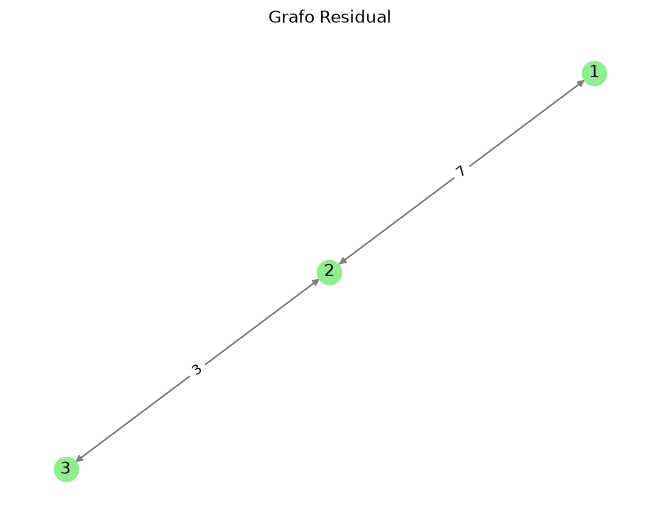

In [76]:
import networkx as nx
import matplotlib.pyplot as plt

# Grafo dirigido con capacidades
G = nx.DiGraph()
G.add_edge(1, 2, capacity=10)
G.add_edge(2, 3, capacity=5)

# Flujo actual simulado
flow_dict = {1: {2: 7}, 2: {3: 3}, 3: {}}

# Construcción del grafo residual
R = nx.DiGraph()

for u in flow_dict:
    for v in flow_dict[u]:
        capacidad = G[u][v]["capacity"]
        flujo = flow_dict[u][v]

        # Capacidad hacia adelante
        if capacidad - flujo > 0:
            R.add_edge(u, v, residual=capacidad - flujo)

        # Capacidad hacia atrás
        if flujo > 0:
            R.add_edge(v, u, residual=flujo)

# Dibujo grafo residual
pos = nx.spring_layout(R, seed=42)
nx.draw(R, pos, with_labels=True, node_color="lightgreen", edge_color="gray", arrows=True)

# Capacidades residuales
edge_labels = nx.get_edge_attributes(R, "residual")
nx.draw_networkx_edge_labels(R, pos, edge_labels=edge_labels)

plt.title("Grafo Residual")
plt.show()

In [79]:
import pandas as pd

# Datos de la tabla
data = {
    "ALGORITMO": [
        "Árbol de expansión mínima",
        "Ruta más corta",
        "Trayectorias aumentadas (flujo máximo)"
    ],
    "TIPO DE RED": [
        "No dirigida",
        "No dirigida (con origen/destino)",
        "Dirigida"
    ],
    "OBJETIVO": [
        "Conectar todos los nodos al menor costo total.",
        "Encontrar la trayectoria de menor distancia entre dos nodos.",
        "Maximizar el flujo del origen al destino."
    ]
}
tabla = pd.DataFrame(data)
tabla

,ALGORITMO,TIPO DE RED,OBJETIVO
0,Árbol de expansión mínima,No dirigida,Conectar todos los nodos al menor costo total.
1,Ruta más corta,No dirigida (con origen/destino),Encontrar la trayectoria de menor distancia en...
2,Trayectorias aumentadas (flujo máximo),Dirigida,Maximizar el flujo del origen al destino.


Con esta tabla de Resumen de los 3 algoritmos de la unidad podemos concluir que:
## Árbol de Expansión Mínima (MST)

- Se aplica en redes no dirigidas.

- Su objetivo es conectar todos los nodos con el menor costo total posible.

- Es útil en problemas de infraestructura (redes eléctricas, tuberías, carreteras).

## Problema de la Ruta Más Corta

- Se usa en redes no dirigidas con un origen y destino definidos.

- Busca la trayectoria con la menor distancia o costo.

- Es fundamental en navegación GPS, logística y planificación de rutas.

## Flujo Máximo (Trayectorias aumentadas)

- Se trabaja en redes dirigidas con capacidades en las aristas.

- El objetivo es maximizar el flujo desde una fuente hasta un sumidero.

- Se aplica en transporte de recursos, telecomunicaciones y problemas de asignación.